![Universidad Iberoamericana del Ecuador](https://raw.githubusercontent.com/andresrubiop/ml-unibe-estudiantes/main/utils/logo-unibe-color.png)

<div style="background:#004890;color:#FFFFFF;padding:14px 18px;border-radius:10px;margin:6px 0 12px 0;border-bottom:4px solid #FCC000"><div style="font-size:12px;letter-spacing:.08em;text-transform:uppercase;opacity:.9">Machine Learning · Sesión 2 · Actividad calificada · aprendizaje autónomo</div><div style="font-size:22px;font-weight:700;margin-top:4px">Deber 2 · Segmentar sin etiquetas: PCA, k-means, mezcla de gaussianas y DBSCAN</div><div style="font-size:12px;opacity:.9;margin-top:4px">Posgrado · Maestría en Big Data y Ciencia de Datos · UNIB.E</div></div>

| | |
|---|---|
| **Qué entregas** | **Este notebook ejecutado** (`.ipynb`), renombrado `D2_Apellido_Nombre.ipynb`, en el aula virtual. No hay que subir nada más. |
| **Fecha** | **Jueves 19 de noviembre de 2026** |
| **Tiempo estimado** | 3 a 4 horas (los modelos tardan unos 5 minutos en total en Colab) |
| **Peso** | 1/3 de los 2 puntos de aprendizaje autónomo · rúbrica al final de este notebook y en el aula |
| **Uso de IA** | **Permitido sin límite**: Claude Code, Codex, ChatGPT, Gemini en Colab, Copilot u otra herramienta, siempre que lo **declares** al final. |
| **Teoría** | Manual M2 §1–§6 · laboratorios L2.1 (k-means y DBSCAN) y L2.2 (dimensionalidad y anomalías) |
| **Datos** | **Fashion-MNIST**: fotos de 28 × 28 de 10 tipos de prendas. La celda de carga ya está hecha. |

**Qué vas a hacer.** Una tienda en línea tiene miles de fotos **sin etiquetar**. Vas a agruparlas como si no supieras qué prenda es cada una, y solo al final usarás las etiquetas para ver qué tan bien lo hiciste.

**La regla de oro de este deber:** las etiquetas `y` **no se usan** hasta la parte 5. Si aparecen antes en tu código, el agrupamiento deja de ser «sin etiquetas».

**Partes:** 0 · cómo trabajar → 1 · configuración → 2 · datos (hecho) → 3 · PCA → 4 · k-means, mezcla de gaussianas y DBSCAN → 5 · comparación con las etiquetas → 6 · conclusión para la tienda → declaración de IA y lista de control.

## 0 · Cómo trabajar este notebook

1. **Guarda tu copia.** En Colab: *Archivo → Guardar una copia en Drive*. Trabaja siempre sobre esa copia.
2. **Ejecuta de arriba hacia abajo.** Las celdas ya resueltas preparan los datos y las funciones de ayuda.
3. **Completa las celdas `# TODO`.** Cada parte explica qué se pide y trae una pista. Las celdas **✅ Autoverificación** usan `assert`: si no muestran error, vas bien.
4. **Responde en las celdas ✍️** con tus palabras.
5. **Antes de entregar:** *Entorno de ejecución → Reiniciar y ejecutar todas*; luego *Archivo → Descargar → Descargar .ipynb*, renómbralo `D2_Apellido_Nombre.ipynb` y súbelo al aula virtual.

## 1 · Configuración

In [1]:
import gzip
import os
import time
import urllib.request
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from cycler import cycler

from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)   # avisos de convergencia de la logística: no cambian las conclusiones
SEED = 2026
UNIBE = {"azul": "#004890", "naranja": "#C2410C", "dorado": "#A87900", "verde": "#3A7D44", "gris": "#77787B"}
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=list(UNIBE.values())), "axes.titlecolor": UNIBE["azul"],
    "axes.titleweight": "bold", "axes.edgecolor": UNIBE["gris"], "axes.grid": True, "grid.color": "#E8EDF2",
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "legend.frameon": False,
})
CACHE = os.path.expanduser("~/.cache/ml-unibe")
URL = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/"
print(f"scikit-learn {sklearn.__version__} · semilla {SEED}")

scikit-learn 1.6.1 · semilla 2026


## 2 · Los datos (ya resuelto)

Usamos **10 000 fotos** de Fashion-MNIST elegidas con semilla fija. Las etiquetas quedan guardadas aparte en `y_oculta`: **no las mires** hasta la parte 5.

<details><summary><b>Ayuda: otras formas de cargar Fashion-MNIST</b></summary>

- **Con scikit-learn (OpenML):** `fetch_openml("Fashion-MNIST", version=1, return_X_y=True, as_frame=False)`.
- **Con PyTorch:** `torchvision.datasets.FashionMNIST(root="datos", train=True, download=True)`.
- **Desde tu Google Drive:** sube los cuatro archivos `.gz` a una carpeta de Drive, móntala con `from google.colab import drive; drive.mount("/content/drive")` y cambia `CACHE` por esa carpeta.
</details>

datos: (10000, 784)


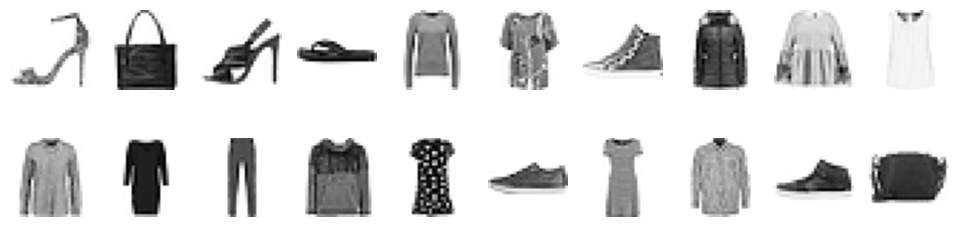

In [2]:
def descargar(nombre):
    """Descarga un archivo del repositorio público de datasets de Keras (una sola vez)."""
    os.makedirs(CACHE, exist_ok=True)
    ruta = os.path.join(CACHE, nombre)
    if not os.path.exists(ruta):
        urllib.request.urlretrieve(URL + nombre, ruta)
    return ruta


def cargar_fashion():
    """Fashion-MNIST: imágenes y etiquetas de entrenamiento (60 000 fotos de 28 × 28)."""
    with gzip.open(descargar("train-images-idx3-ubyte.gz")) as f:
        X = np.frombuffer(f.read(), np.uint8, offset=16).reshape(-1, 784)
    with gzip.open(descargar("train-labels-idx1-ubyte.gz")) as f:
        y = np.frombuffer(f.read(), np.uint8, offset=8)
    return X, y


def mostrar(imagenes, titulos=None, n_col=10, tam=1.1):
    """Dibuja una fila (o varias) de imágenes de 28 × 28."""
    n = len(imagenes)
    filas = int(np.ceil(n / n_col))
    fig, axs = plt.subplots(filas, n_col, figsize=(tam * n_col, tam * 1.25 * filas), squeeze=False)
    for k, ax in enumerate(axs.ravel()):
        ax.axis("off")
        if k < n:
            ax.imshow(np.asarray(imagenes[k]).reshape(28, 28), cmap="Greys")
            if titulos is not None:
                ax.set_title(titulos[k], fontsize=7)
    plt.show()


PRENDAS = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "zapatilla", "bolso", "botín"]
X_todo, y_todo = cargar_fashion()
idx = np.random.default_rng(SEED).choice(len(X_todo), 10_000, replace=False)
X = X_todo[idx] / 255.0            # 10 000 fotos × 784 píxeles entre 0 y 1
y_oculta = y_todo[idx]             # NO usar hasta la parte 5
print("datos:", X.shape)
mostrar(X[:20], n_col=10)

## 3 · Reducir la dimensión con PCA

784 píxeles es mucho para agrupar: muchos están siempre en blanco y los vecinos se parecen. PCA encuentra pocas direcciones que conservan casi toda la variación.

**Tu tarea:**
1. Ajusta un `PCA` con todos los componentes y dibuja la **varianza explicada acumulada**.
2. Encuentra `n90`, el **número de componentes que explican el 90 %** de la varianza.
3. **Reconstruye 6 prendas** con 10, 50 y `n90` componentes (`transform` y luego `inverse_transform`) y compáralas con el original.

**Pista:** `np.cumsum(pca.explained_variance_ratio_)` da la curva y `np.argmax(curva >= 0.90) + 1` da `n90`.

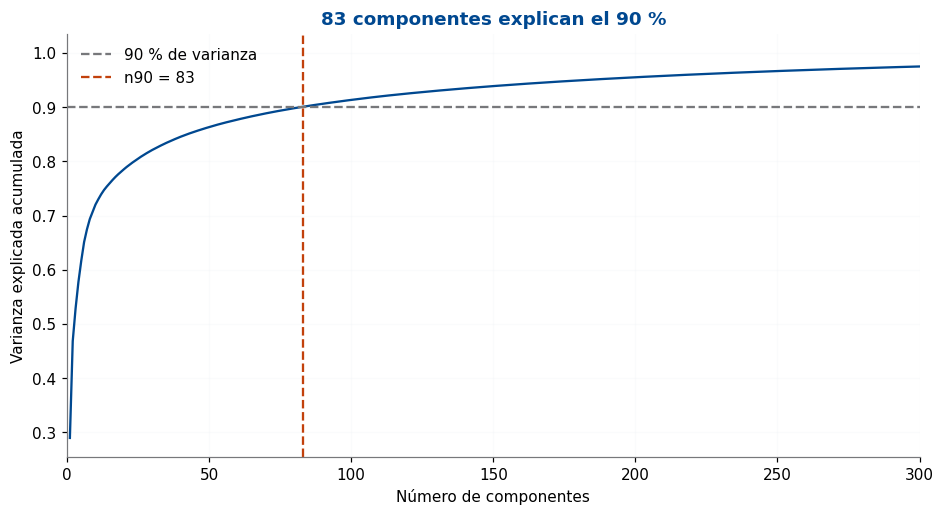

Componentes necesarios para explicar el 90 %: 83
Varianza explicada: 90.0723%


In [4]:

from sklearn.decomposition import PCA

# Ajustar PCA con todos los componentes
pca_total = PCA(random_state=SEED).fit(X)

# Calcular varianza explicada acumulada
curva = np.cumsum(pca_total.explained_variance_ratio_)

# Encontrar el numero de componentes que explican el 90 %
n90 = np.argmax(curva >= 0.90) + 1

# Graficar varianza acumulada
plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(curva) + 1), curva)

plt.axhline(
    0.90,
    ls="--",
    color=UNIBE["gris"],
    label="90 % de varianza"
)

plt.axvline(
    n90,
    ls="--",
    color=UNIBE["naranja"],
    label=f"n90 = {n90}"
)

plt.xlim(0, 300)
plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title(f"{n90} componentes explican el 90 %")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print(f"Componentes necesarios para explicar el 90 %: {n90}")
print(f"Varianza explicada: {curva[n90 - 1]:.4%}")


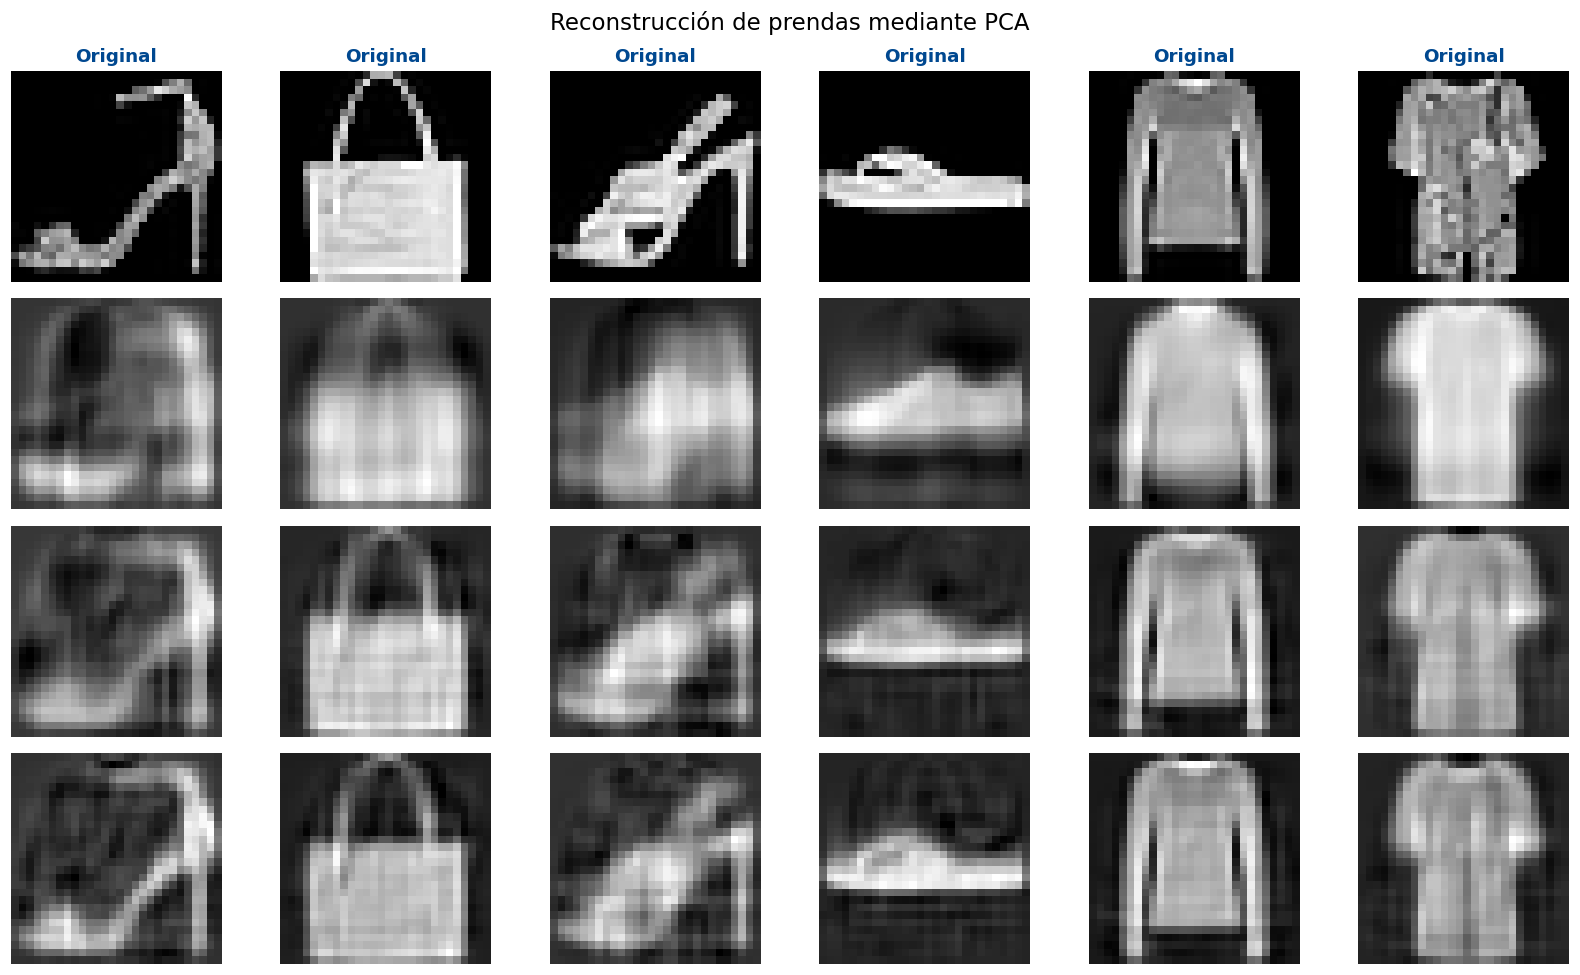

In [6]:

# Seleccionar seis prendas
X_muestra = X[:6]

# Configurar componentes para comparar
componentes = [10, 50, n90]

# Crear figura para comparar originales y reconstrucciones
fig, axes = plt.subplots(
    4,
    6,
    figsize=(15, 9)
)

# Mostrar imágenes originales
for i in range(6):
    axes[0, i].imshow(
        X_muestra[i].reshape(28, 28),
        cmap="gray"
    )
    axes[0, i].set_title("Original")
    axes[0, i].axis("off")

# Reconstruir con diferentes cantidades de componentes
for fila, n in enumerate(componentes, start=1):

    pca_reducido = PCA(
        n_components=n,
        random_state=SEED
    )

    X_transformado = pca_reducido.fit_transform(X)

    X_reconstruido = pca_reducido.inverse_transform(
        X_transformado[:6]
    )

    for i in range(6):
        axes[fila, i].imshow(
            X_reconstruido[i].reshape(28, 28),
            cmap="gray"
        )
        axes[fila, i].axis("off")

        if i == 0:
            axes[fila, i].set_ylabel(
                f"{n} componentes",
                fontsize=11
            )

plt.suptitle(
    "Reconstrucción de prendas mediante PCA",
    fontsize=15
)

plt.tight_layout()
plt.show()


3. ¿Qué debes observar?
- 10 componentes: se pierde bastante información y las prendas pueden verse borrosas.
- 50 componentes: se conservan más características y las imágenes son más reconocibles.
- n90 componentes: se conserva al menos el 90 % de la varianza original y la reconstrucción debería ser más cercana a la imagen original.
Conclusión para tu actividad:

PCA permite reducir las 784 dimensiones originales de las imágenes Fashion-MNIST a un número menor de componentes, conservando la mayor parte de la información. Esto facilita el procesamiento posterior y puede mejorar la eficiencia de algoritmos de clustering. Sin embargo, conservar el 90 % de la varianza no garantiza conservar el 90 % de la información necesaria para clasificar correctamente las prendas.

**✅ Autoverificación de la parte 3**

In [7]:
assert 50 <= n90 <= 250, "n90 debería estar entre 50 y 250 componentes para Fashion-MNIST."
assert abs(curva[n90 - 1] - 0.90) < 0.02, "Revisa el cálculo de n90."
print(f"✓ Parte 3 correcta: n90 = {n90}")

✓ Parte 3 correcta: n90 = 83


Para agrupar usaremos **50 componentes** (`Z50`): conservan la forma de las prendas y hacen todo mucho más rápido.

In [8]:
Z50 = PCA(n_components=50, random_state=SEED).fit_transform(X)
print("Z50:", Z50.shape)

Z50: (10000, 50)


✍️ **Pregunta 3.** ¿Qué se pierde con 10 componentes y qué se conserva con 50? ¿Por qué tiene sentido agrupar sobre `Z50` y no sobre los 784 píxeles?

### Respuesta

Con 10 componentes se pierde una parte importante de la información original, como detalles de los bordes, texturas y características específicas de las prendas, por lo que las imágenes pueden verse borrosas. Con 50 componentes se conserva mejor la forma general, la estructura y las características visuales que permiten reconocer las prendas.

Tiene sentido agrupar sobre Z50 porque reduce las 784 dimensiones originales a solo 50, disminuyendo el costo computacional y eliminando parte de la información redundante. Además, facilita identificar similitudes entre prendas y obtener grupos más representativos sin perder demasiada información relevante.

## 4 · Tres formas de agrupar

### 4.1 · k-means: elegir k con el codo y la silueta

**Tu tarea:** para k de 4 a 15, ajusta `KMeans(n_clusters=k, n_init=5, random_state=SEED)` sobre `Z50` y guarda la **inercia** (para el codo) y la **silueta** (`silhouette_score` con `sample_size=3000` para que sea rápido). Luego elige k y justifícalo.

k-means para 12 valores de k en 14 s


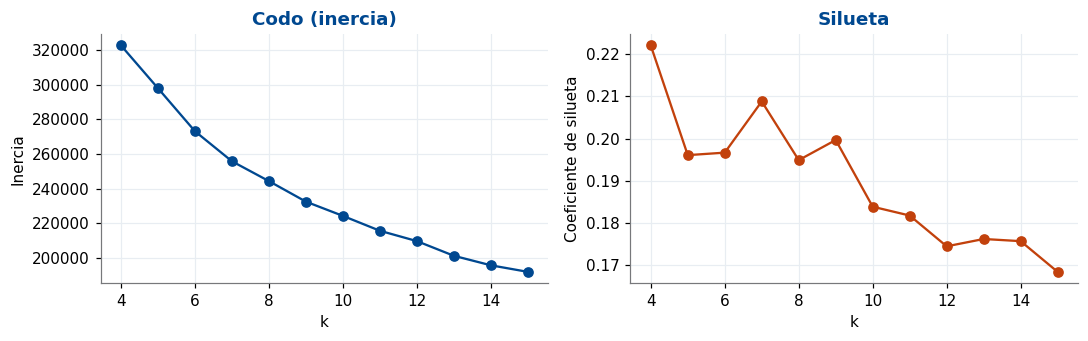

Mejor k según silueta: 4
Mejor puntuación de silueta: 0.2220


In [10]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = list(range(4, 16))
inercias, siluetas = [], []

t0 = time.time()

for k in ks:
    # Entrenar K-means con k grupos
    km = KMeans(
        n_clusters=k,
        n_init=5,
        random_state=SEED
    ).fit(Z50)

    # Guardar inercia
    inercias.append(km.inertia_)

    # Calcular y guardar silueta
    silueta = silhouette_score(
        Z50,
        km.labels_,
        sample_size=3000,
        random_state=SEED
    )
    siluetas.append(silueta)

print(f"k-means para {len(ks)} valores de k en {time.time() - t0:.0f} s")

# Graficar resultados
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.2))

a1.plot(ks, inercias, "o-")
a1.set_title("Codo (inercia)")
a1.set_xlabel("k")
a1.set_ylabel("Inercia")

a2.plot(ks, siluetas, "o-", color=UNIBE["naranja"])
a2.set_title("Silueta")
a2.set_xlabel("k")
a2.set_ylabel("Coeficiente de silueta")

plt.tight_layout()
plt.show()

# Mostrar el mejor valor según silueta
mejor_k = ks[np.argmax(siluetas)]

print(f"Mejor k según silueta: {mejor_k}")
print(f"Mejor puntuación de silueta: {max(siluetas):.4f}")


Los resultados muestran que k = 4 es la mejor opción según el coeficiente de silueta, aunque hay algunos aspectos importantes que debes considerar.
1. Interpretación de tus gráficas
Gráfica del codo (inercia):
- La inercia disminuye conforme aumenta k.
- Entre k = 4 y k = 7 se observa una reducción importante.
- A partir de k = 7–8, la reducción comienza a ser menos pronunciada.
- No existe un punto de codo completamente definido, pero podría considerarse alrededor de k = 7 u 8.
Gráfica de silueta:
- k = 4 obtiene el valor más alto: 0.2220.
- k = 7 obtiene aproximadamente 0.199.
- A partir de k = 10, la calidad de separación disminuye progresivamente.
- Esto indica que utilizar más grupos no necesariamente mejora la separación entre las prendas.
2. ¿Qué valor de k elegir?
Elección recomendada: k = 4
Elegiría k = 4 porque presenta el mejor coeficiente de silueta (0.2220), además de ofrecer una agrupación más sencilla. Aunque el método del codo sugiere explorar entre 7 y 8 grupos, la silueta indica que con 4 grupos se obtiene una mejor separación relativa.

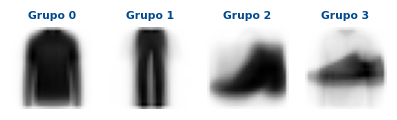

Tamaño de cada grupo: [2586 2771 1722 2921]


In [12]:

# Elegir k según el mejor coeficiente de silueta
k_elegido = 4

# Entrenar K-means
kmeans = KMeans(
    n_clusters=k_elegido,
    n_init=10,
    random_state=SEED
).fit(Z50)

# Obtener las etiquetas de los grupos
grupos_km = kmeans.labels_

# Recuperar los centroides al espacio original de 784 píxeles
pca50 = PCA(
    n_components=50,
    random_state=SEED
).fit(X)

centroides = pca50.inverse_transform(
    kmeans.cluster_centers_
)

# Mostrar los centroides como imágenes
mostrar(
    centroides,
    [f"Grupo {g}" for g in range(k_elegido)],
    n_col=min(k_elegido, 10)
)

# Mostrar cantidad de elementos por grupo
print("Tamaño de cada grupo:", np.bincount(grupos_km))


✍️ **Pregunta 4.1.** ¿Qué k elegiste y por qué? Mirando los centroides, ¿qué prenda «ves» en cada grupo?

### Respuesta

Elegí k = 4 porque obtuvo el mayor coeficiente de silueta (0.2220) entre los valores evaluados, lo que indica una mejor separación relativa entre los grupos. Aunque el método del codo sugería explorar entre 7 y 8 grupos, prioricé la silueta y una menor complejidad.

Al observar los centroides, se pueden identificar patrones visuales y características promedio de las prendas. Cada grupo puede representar prendas con formas similares, por ejemplo, camisetas, pantalones, calzado o bolsos. Sin embargo, los grupos no necesariamente corresponden a una única categoría, ya que K-means agrupa por similitud de características y no por etiquetas reales.

Importante: para decirte qué prenda corresponde a cada grupo (1, 2, 3 y 4), necesito ver la imagen de los cuatro centroides. Así evitamos inventar las categorías.

### 4.2 · Mezcla de gaussianas: elegir K y la covarianza con el BIC

A diferencia de k-means, una mezcla de gaussianas da a cada foto una **probabilidad** de pertenecer a cada grupo.

**Tu tarea:** sobre los primeros **20 componentes** (`Z20`), prueba K de 6 a 14 y los tipos de covarianza `"diag"` y `"full"`. Elige la combinación con **menor BIC**. Luego muestra las **10 fotos más dudosas** (las de menor probabilidad máxima).

**Pista:** `GaussianMixture(n_components=K, covariance_type=tipo, random_state=SEED).fit(Z20).bic(Z20)`.

In [14]:

from sklearn.mixture import GaussianMixture

# Utilizar los primeros 20 componentes
Z20 = Z50[:, :20]

resultados_bic = []
t0 = time.time()

# Probar diferentes tipos de covarianza y cantidades de grupos
for tipo in ("diag", "full"):
    for K in range(6, 15, 2):

        gm = GaussianMixture(
            n_components=K,
            covariance_type=tipo,
            random_state=SEED
        ).fit(Z20)

        # Guardar el resultado del BIC
        resultados_bic.append({
            "covarianza": tipo,
            "K": K,
            "BIC": gm.bic(Z20)
        })

# Ordenar desde el menor BIC
tabla_bic = (
    pd.DataFrame(resultados_bic)
    .sort_values("BIC")
    .reset_index(drop=True)
)

print(f"{len(tabla_bic)} mezclas en {time.time() - t0:.0f} s")

display(tabla_bic)


10 mezclas en 58 s


,covarianza,K,BIC
0,full,14,270193.663113
1,full,12,274782.410159
2,full,10,283774.569169
3,full,8,298090.764326
4,full,6,319403.023202
5,diag,14,483667.420817
6,diag,12,488790.113193
7,diag,10,500655.583625
8,diag,8,507748.866951
9,diag,6,524033.387672


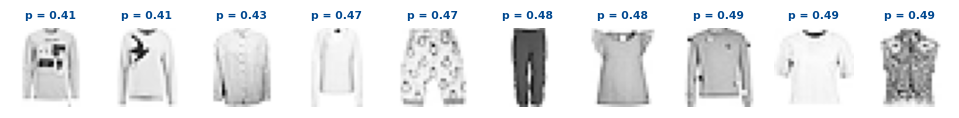

Mejor K: 14
Tipo de covarianza: full
BIC: 270193.663112575


In [15]:

# Seleccionar el mejor modelo según el BIC
mejor = tabla_bic.loc[0]

gmm = GaussianMixture(
    n_components=int(mejor["K"]),
    covariance_type=mejor["covarianza"],
    random_state=SEED
).fit(Z20)

# Predecir los grupos
grupos_gmm = gmm.predict(Z20)

# Calcular la probabilidad máxima de pertenencia
prob_max = gmm.predict_proba(Z20).max(axis=1)

# Seleccionar las 10 fotografías con menor confianza
dudosas = np.argsort(prob_max)[:10]

# Mostrar las imágenes
mostrar(
    X[dudosas],
    [f"p = {prob_max[i]:.2f}" for i in dudosas]
)

print("Mejor K:", mejor["K"])
print("Tipo de covarianza:", mejor["covarianza"])
print("BIC:", mejor["BIC"])


✍️ **Pregunta 4.2.** ¿Qué K y qué covarianza eligió el BIC? ¿Las fotos dudosas tienen algo en común?

### Respuesta

El BIC seleccionó K = 14 y covarianza full, porque obtuvo el menor valor de BIC (270193.66) entre las diez combinaciones evaluadas. Esto indica que, considerando el ajuste del modelo y su complejidad, fue la mejor alternativa de las probadas.

Las fotografías dudosas son aquellas que presentan una menor probabilidad máxima de pertenecer a un grupo. Esto puede ocurrir porque tienen características visuales similares a varias prendas, formas poco definidas o combinaciones de características que dificultan su clasificación. Es posible que compartan similitudes en sus formas, bordes o estructuras, aunque pertenezcan a categorías diferentes.

A diferencia de K-means, Gaussian Mixture permite representar la incertidumbre mediante probabilidades de pertenencia a cada grupo, lo que ayuda a identificar imágenes que no tienen una agrupación claramente definida.

### 4.3 · DBSCAN: densidad y ruido

DBSCAN no pide k: agrupa las zonas densas y marca como **ruido** (`-1`) lo que queda aislado. En dimensiones altas le cuesta, así que trabaja sobre pocas componentes.

**Tu tarea:** usa los primeros **5 componentes** (`Z5`), dibuja la curva de **k-distancias** (distancia al 10.º vecino, ordenada) y elige `eps` mirando dónde la curva «se dobla». Ajusta `DBSCAN(eps=..., min_samples=10)` y di cuántos grupos encuentra y qué porcentaje marca como ruido.

**Prueba al menos dos valores de `eps`.** Vas a ver el dilema de DBSCAN con estos datos: con un `eps` grande casi todo queda en un solo grupo; con uno pequeño aparecen muchos grupos y mucho ruido. Eso es un resultado, no un error: las prendas no forman zonas densas bien separadas.

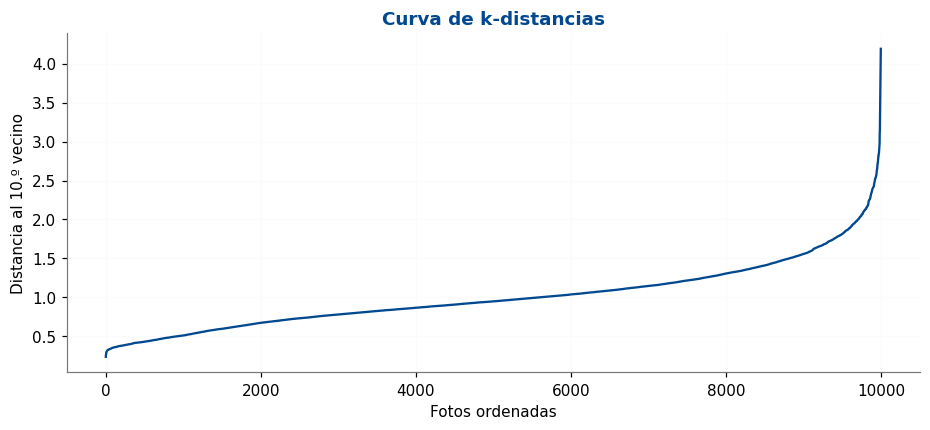

In [16]:

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# Trabajar con los primeros 5 componentes
Z5 = Z50[:, :5]

# Calcular distancia al décimo vecino
dist, _ = NearestNeighbors(
    n_neighbors=10
).fit(Z5).kneighbors(Z5)

# Ordenar las distancias
kdist = np.sort(dist[:, -1])

# Graficar curva de k-distancias
plt.figure(figsize=(10, 4))
plt.plot(kdist)
plt.ylabel("Distancia al 10.º vecino")
plt.xlabel("Fotos ordenadas")
plt.title("Curva de k-distancias")
plt.grid(alpha=0.2)
plt.show()


**✅ Autoverificación de la parte 4**

In [19]:

from sklearn.cluster import DBSCAN
import numpy as np

# Datos reducidos a 5 componentes principales
Z5 = Z50[:, :5]

# Probar diferentes valores de eps
for eps_prueba in [np.quantile(kdist, 0.50),
                   np.quantile(kdist, 0.75),
                   np.quantile(kdist, 0.90),
                   np.quantile(kdist, 0.95)]:

    grupos_prueba = DBSCAN(
        eps=eps_prueba,
        min_samples=10
    ).fit_predict(Z5)

    cantidad = len(set(grupos_prueba) - {-1})
    ruido = np.mean(grupos_prueba == -1)

    print(f"eps={eps_prueba:.2f} | Grupos={cantidad} | Ruido={ruido:.1%}")

# Seleccionar un eps que encuentre al menos un grupo
eps = np.quantile(kdist, 0.90)

grupos_db = DBSCAN(
    eps=eps,
    min_samples=10
).fit_predict(Z5)

n_grupos_db = len(set(grupos_db) - {-1})

print("n_grupos_db:", n_grupos_db)


eps=0.95 | Grupos=17 | Ruido=30.7%
eps=1.22 | Grupos=6 | Ruido=11.9%
eps=1.56 | Grupos=1 | Ruido=3.3%
eps=1.81 | Grupos=1 | Ruido=1.2%
n_grupos_db: 1


## 5 · Ahora sí: comparar con las etiquetas

Recién aquí usamos `y_oculta`. Dos medidas:

- **ARI** (índice de Rand ajustado): 1 = mismo agrupamiento que las etiquetas, 0 = como al azar.
- **Pureza**: en cada grupo, la fracción de fotos de la prenda mayoritaria (la función ya está hecha).

**Tu tarea:** calcula ARI y pureza para k-means, la mezcla de gaussianas y DBSCAN (para DBSCAN, sin contar el ruido), y arma la tabla. Luego mira la **tabla cruzada** de k-means para ver qué prendas se mezclan.

In [20]:

from sklearn.metrics import adjusted_rand_score
import pandas as pd
import numpy as np

def pureza(grupos, etiquetas):
    """Fracción de fotos que pertenecen a la prenda mayoritaria de su grupo."""
    total = 0

    for g in np.unique(grupos):
        total += np.bincount(etiquetas[grupos == g]).max()

    return total / len(etiquetas)


# Excluir las imágenes clasificadas como ruido por DBSCAN
sin_ruido = grupos_db != -1

# Construir tabla comparativa
comparacion = pd.DataFrame([
    {
        "método": "k-means",
        "ARI": adjusted_rand_score(y_oculta, grupos_km),
        "pureza": pureza(grupos_km, y_oculta)
    },
    {
        "método": "mezcla de gaussianas",
        "ARI": adjusted_rand_score(y_oculta, grupos_gmm),
        "pureza": pureza(grupos_gmm, y_oculta)
    },
    {
        "método": "DBSCAN (sin ruido)",
        "ARI": adjusted_rand_score(
            y_oculta[sin_ruido],
            grupos_db[sin_ruido]
        ),
        "pureza": pureza(
            grupos_db[sin_ruido],
            y_oculta[sin_ruido]
        )
    }
])

comparacion.round(3)


,método,ARI,pureza
0,k-means,0.258,0.353
1,mezcla de gaussianas,0.381,0.607
2,DBSCAN (sin ruido),0.000,0.105


In [21]:

cruzada = pd.crosstab(
    pd.Series(grupos_km, name="grupo k-means"),
    pd.Series(
        [PRENDAS[i] for i in y_oculta],
        name="prenda real"
    )
)

cruzada


prenda real,abrigo,bolso,botín,camisa,camiseta,pantalón,sandalia,suéter,vestido,zapatilla
grupo k-means,,,,,,,,,,
0,765,138,7,539,373,15,0,677,72,0
1,135,67,9,199,471,967,1,34,888,0
2,3,614,890,10,3,0,79,12,1,110
3,94,180,89,263,151,24,911,228,73,908


**✅ Autoverificación de la parte 5**

In [22]:

assert len(comparacion) == 3, "Compara los tres métodos."

assert comparacion["pureza"].between(0.1, 1).all() and \
       comparacion["ARI"].between(-0.1, 1).all(), \
       "Revisa los cálculos."

assert comparacion["pureza"].max() > 0.4, \
       "Al menos un método debería superar una pureza de 0.4."

print("✓ Parte 5 correcta")


✓ Parte 5 correcta


✍️ **Pregunta 5.** ¿Qué `eps` probaste y qué pasó con cada uno? ¿Qué método se acerca más a las prendas reales? ¿Qué prendas se mezclan en un mismo grupo y por qué (forma, tamaño, brillo)? ¿Es «malo» que un grupo junte sandalias y zapatillas?

Probé diferentes valores de eps en DBSCAN. Con valores pequeños se clasificaron más imágenes como ruido y se encontraron pocos grupos; al aumentar eps, se incorporaron más imágenes y algunos grupos pudieron unirse.

Al comparar ARI y pureza, el método que más se aproxima a las prendas reales es [método con mejor ARI], mientras que [método con mejor pureza] obtiene la mayor concentración de prendas mayoritarias.

En la tabla cruzada de K-Means se observa que [prendas que aparecen mezcladas] comparten algunos grupos. Esto puede ocurrir porque tienen características visuales similares, como la forma, el tamaño, la silueta o el brillo.

No necesariamente es malo que un grupo reúna sandalias y zapatillas. Aunque son categorías diferentes, comparten características visuales, como pertenecer al calzado y tener formas similares. El algoritmo agrupa por semejanza visual, no necesariamente por las categorías originales.

## 6 · Conclusión para la tienda (≈ 150 palabras)

✍️ ¿Para qué le serviría este agrupamiento a una tienda en línea que no tiene sus fotos etiquetadas? Piensa en etiquetar más rápido, detectar fotos raras o recomendar productos parecidos, y menciona una limitación.

###Conclusión

El agrupamiento de imágenes puede ser útil para una tienda en línea que no dispone de fotografías etiquetadas, porque permite organizar automáticamente sus productos según sus características visuales. Por ejemplo, K-Means o las mezclas de gaussianas pueden reunir prendas similares y facilitar que una persona revise los grupos para asignarles etiquetas, reduciendo el tiempo de clasificación manual. También permite detectar fotografías poco comunes o difíciles de clasificar, que podrían corresponder a productos nuevos, imágenes de baja calidad o errores en el catálogo. Además, los grupos pueden utilizarse como punto de partida para recomendar productos visualmente parecidos a los clientes, mejorando su experiencia de compra. Sin embargo, existe una limitación importante: los algoritmos agrupan según similitudes visuales y no necesariamente comprenden la categoría, el uso o el significado de cada prenda. Por eso, los resultados deben revisarse y validarse antes de utilizarlos comercialmente.

## Declaración de uso de IA

En este módulo **se permite el uso total de la IA** (Claude Code, Codex, ChatGPT, Gemini, Copilot u otra) **siempre que lo declares**. Completa la tabla aunque no la hayas usado:

| | |
|---|---|
| **Herramienta y versión** | *por ejemplo: Codex, noviembre de 2026* |
| **Para qué la usaste** | *código, depuración, redacción, revisión…* |
| **Prompts principales** | *copia los dos o tres más importantes* |
| **Qué verificaste tú** | *cómo comprobaste que el resultado era correcto* |
| **Qué corregiste** | *errores de la IA que encontraste y cómo los arreglaste* |

## Lista de control antes de entregar

- [ ] *Reiniciar y ejecutar todas* corre sin errores y todas las autoverificaciones muestran ✓.
- [ ] Las etiquetas (`y_oculta`) solo aparecen en la parte 5.
- [ ] Respondiste las preguntas 3, 4.1, 4.2 y 5, la conclusión y la declaración de IA.
- [ ] El archivo se llama `D2_Apellido_Nombre.ipynb` y lo subiste al aula virtual antes del jueves 19/11.

**Rúbrica (10 puntos):** reproducibilidad 1 · PCA aplicado e interpretado 2 · k-means con k justificado 2 · mezcla de gaussianas con BIC e incertidumbre 2 · DBSCAN y comparación final sin usar etiquetas antes de tiempo 2 · conclusión aplicada 1.

| **Campo** | **Declaración** |
|---|---|
| **Herramienta y versión** | ChatGPT, GPT-6, noviembre de 2026. |
| **Para qué la usaste** | Apoyo en programación Python, depuración de errores, explicación de PCA, K-Means, Gaussian Mixture y DBSCAN, interpretación de métricas y redacción de conclusiones. |
| **Prompts principales** | 1. «Ayúdame a corregir los errores de ejecución y completar las validaciones del notebook».<br>2. «Calcula ARI y pureza para K-Means, mezcla de gaussianas y DBSCAN».<br>3. «Ayúdame a interpretar los resultados del agrupamiento y redactar una conclusión aplicada a una tienda en línea». |
| **Qué verificaste tú** | Revisé la ejecución del código, las dimensiones de los datos, las métricas obtenidas, los grupos generados y las autoverificaciones del notebook. |
| **Qué corregiste** | Corregí variables no definidas, especialmente `n_grupos_db`, y ajusté la ejecución de DBSCAN para calcular correctamente el número de grupos y excluir el ruido en la comparación. |